In [2]:
from config import Config, NetworkKind
from lib import SweepPoint, sweep
from plot import plot_grid_search

results = {}


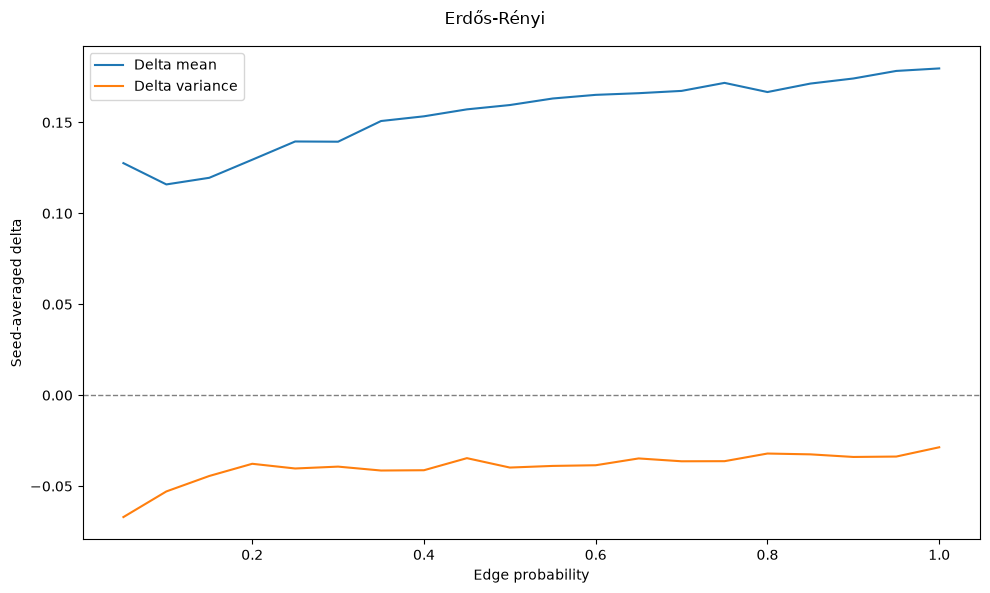

In [3]:
STEP_SIZE = 4
n_agents = Config().n_agents
seeds = range(100)

results[NetworkKind.RANDOM] = sweep(
    NetworkKind.RANDOM,
    [SweepPoint(p_edge=step / 20) for step in range(1, 21)],
    seeds,
)
plot_grid_search(results[NetworkKind.RANDOM], "p_edge")


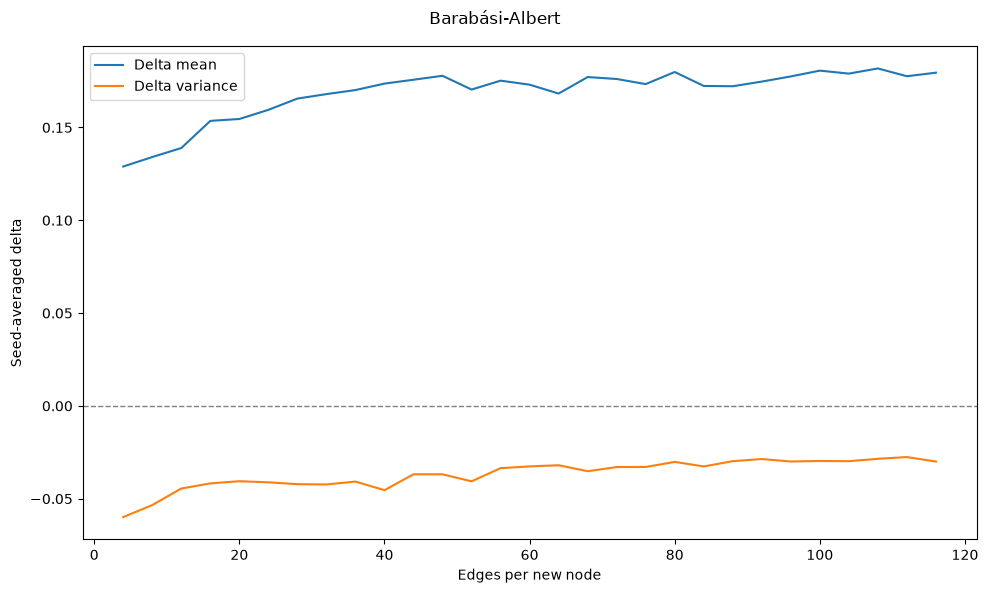

In [4]:
results[NetworkKind.BARBASI] = sweep(
    NetworkKind.BARBASI,
    [SweepPoint(edges=edges) for edges in range(STEP_SIZE, n_agents, STEP_SIZE)],
    seeds,
)
plot_grid_search(results[NetworkKind.BARBASI], "edges")


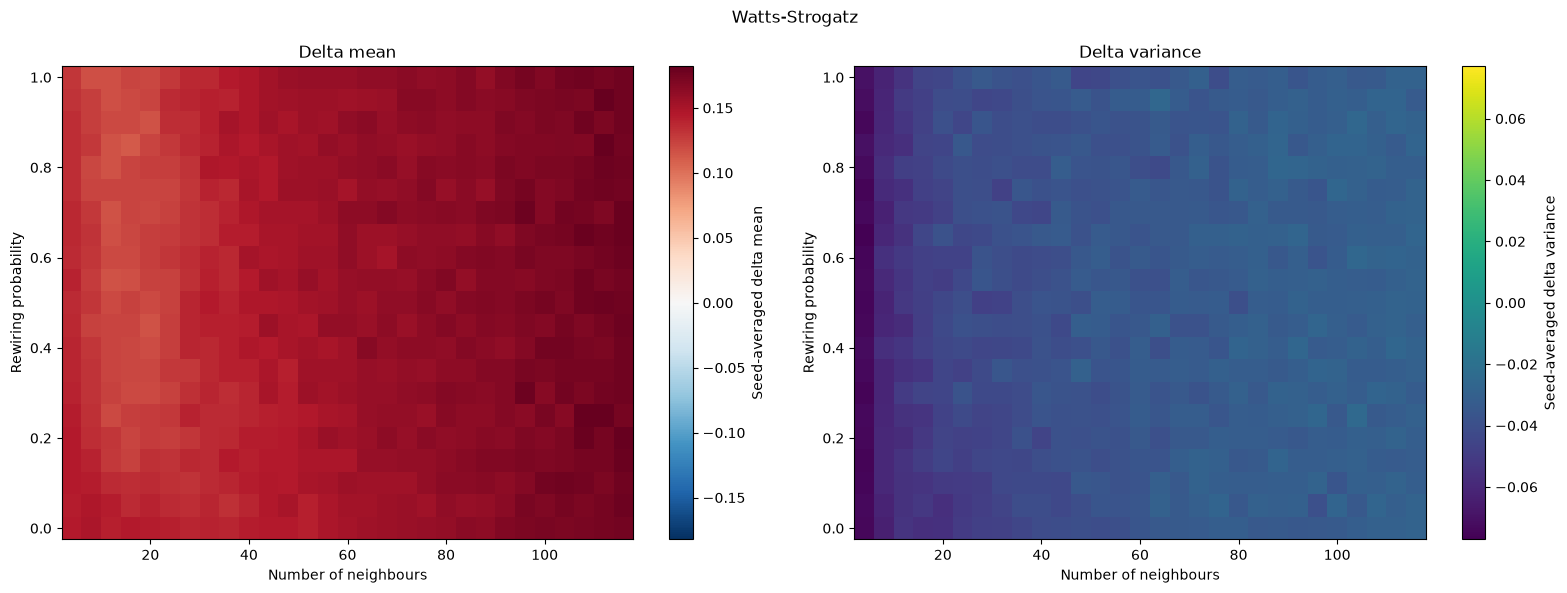

In [5]:
results[NetworkKind.WATTS] = sweep(
    NetworkKind.WATTS,
    [
        SweepPoint(k_neighbors=neighbors, p_rewire=step / 20)
        for neighbors in range(STEP_SIZE, n_agents, STEP_SIZE)
        for step in range(21)
    ],
    seeds,
)
plot_grid_search(results[NetworkKind.WATTS], "k_neighbors", "p_rewire")


In [6]:
for kind, summary in results.items():
    print(kind)
    print(summary)


random
SweepResult(kind=<NetworkKind.RANDOM: 'random'>, highest_delta_mean=0.17967537316920892, average_delta_mean=0.15479061046098666, variance_delta_mean=0.0003681687726776088, average_delta_variance=-0.039228399543618786, seed_means=[0.19119791289328542, 0.16268409567465011, 0.18000561712514834, 0.1581909341463647, 0.18973097030751232, 0.1367082146049416, 0.1514063474586232, 0.20588445132850924, 0.19544267094705867, 0.2008861588933884, 0.12193223333282192, 0.14612555282046988, 0.1726033319871705, 0.1703922898573152, 0.14432161036968422, 0.13961675743816254, 0.16983054152051638, 0.1231940754522882, 0.14261374172023808, 0.12517925045551376, 0.17056538830677181, 0.11686512990359174, 0.11721318514973315, 0.16279378745993925, 0.15090556816687117, 0.1599408495147881, 0.09914638701227463, 0.1353092973519636, 0.1615094591089959, 0.14172662366891453, 0.18838712422956624, 0.18102691460462766, 0.1600854161639817, 0.17316917385557187, 0.15724232566758237, 0.07786442606880253, 0.1409921258157218

In [7]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

random_vs_barbasi = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.BARBASI].seed_means,
)
random_vs_watts = ttest_rel(
    results[NetworkKind.RANDOM].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
barbasi_vs_watts = ttest_rel(
    results[NetworkKind.BARBASI].seed_means,
    results[NetworkKind.WATTS].seed_means,
)
adjusted = multipletests(
    [random_vs_barbasi.pvalue, random_vs_watts.pvalue, barbasi_vs_watts.pvalue],
    method="holm",
)[1]
print("random vs barbasi:", random_vs_barbasi, "Holm p:", adjusted[0])
print("random vs watts:", random_vs_watts, "Holm p:", adjusted[1])
print("barbasi vs watts:", barbasi_vs_watts, "Holm p:", adjusted[2])


random vs barbasi: TtestResult(statistic=np.float64(-4.847569788323228), pvalue=np.float64(4.638771949344166e-06), df=np.int64(99)) Holm p: 9.277543898688331e-06
random vs watts: TtestResult(statistic=np.float64(1.2288352537637939), pvalue=np.float64(0.2220465578190831), df=np.int64(99)) Holm p: 0.2220465578190831
barbasi vs watts: TtestResult(statistic=np.float64(6.260785387200183), pvalue=np.float64(9.89864129160881e-09), df=np.int64(99)) Holm p: 2.969592387482643e-08


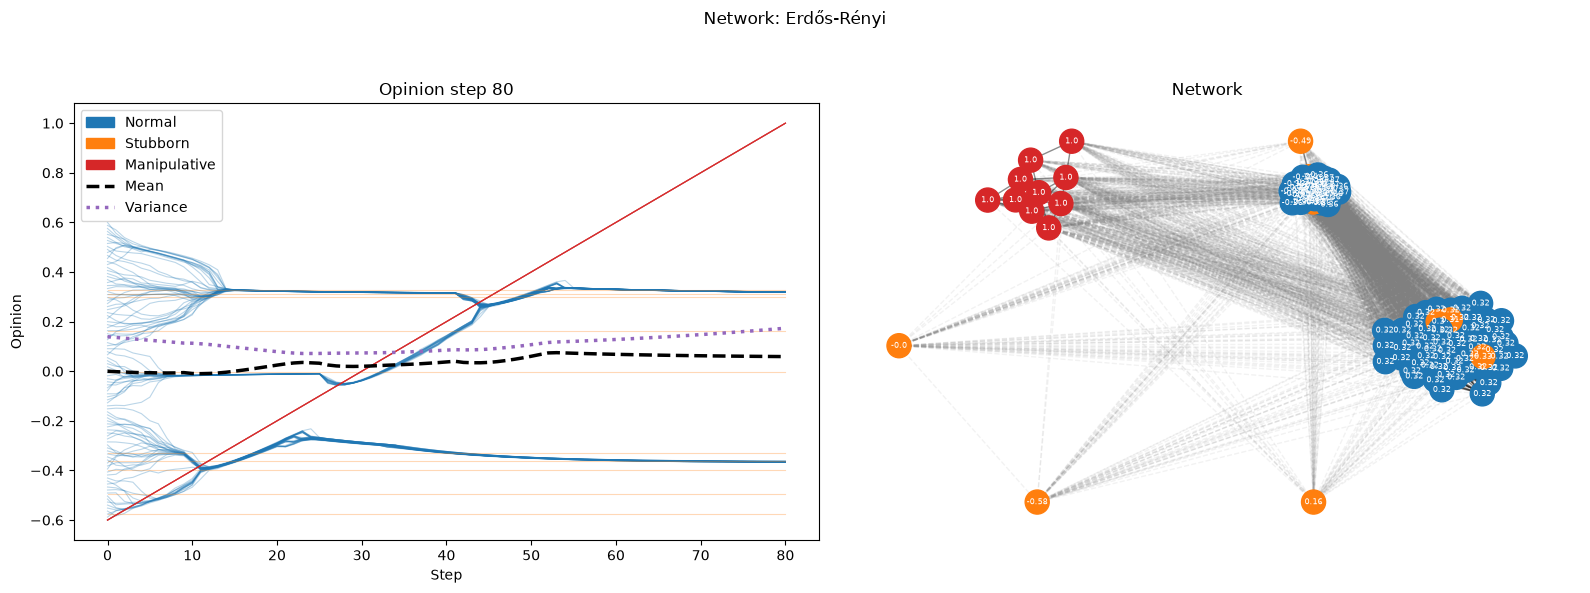

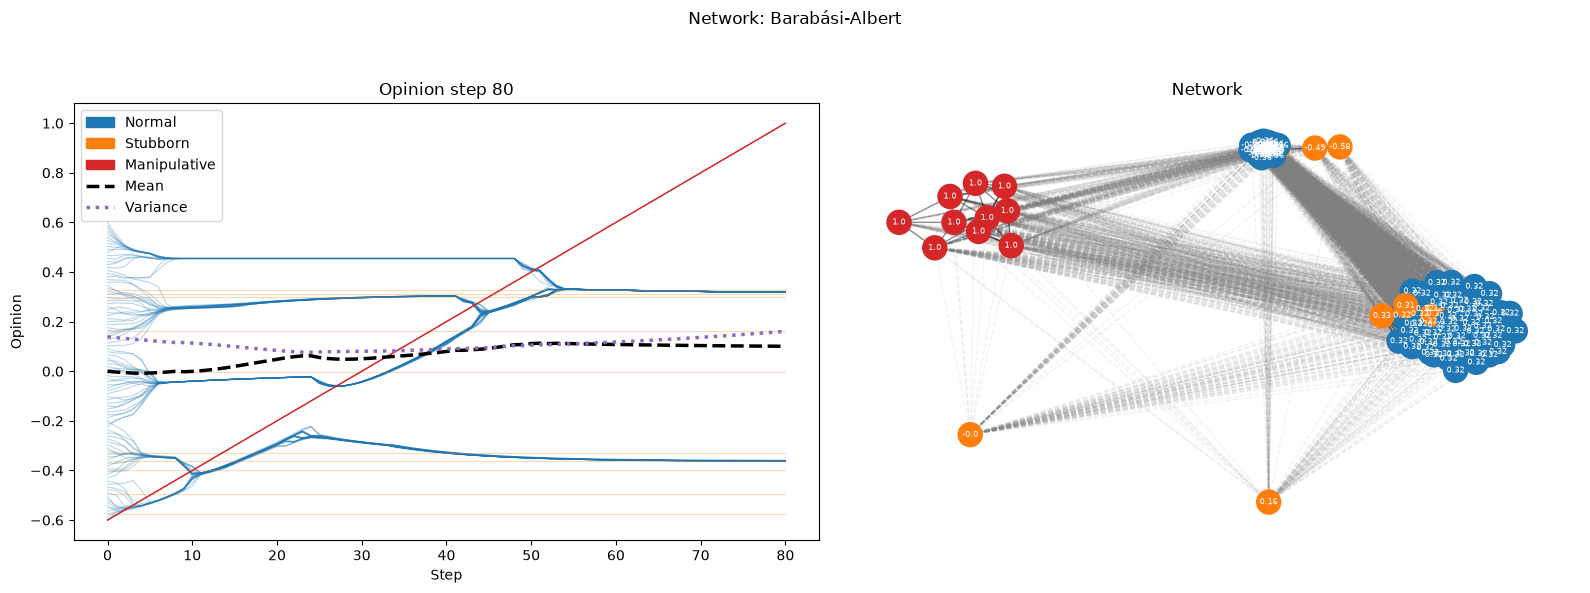

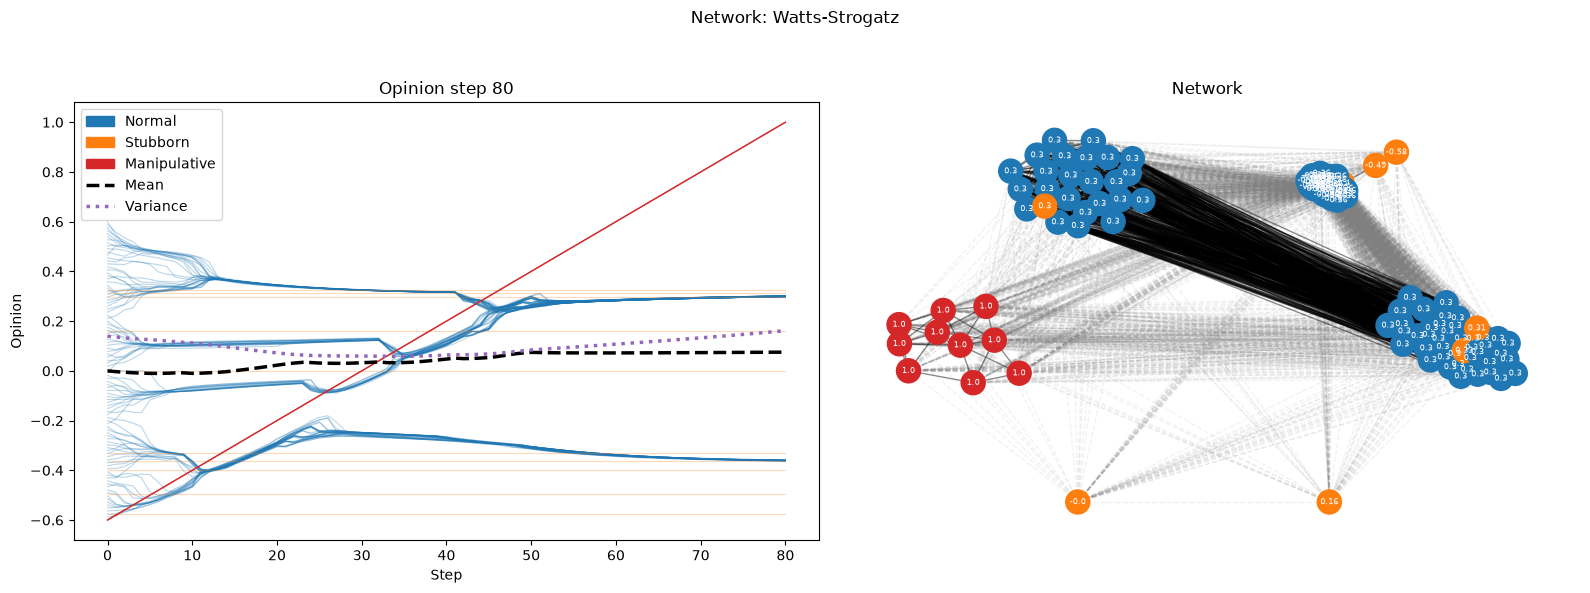

In [8]:
from config import Config
from lib import init_sim, run_one

cfg = Config()
cfg.seed = 10
for kind in cfg.networks:
    sim = init_sim(cfg, kind)
    run_one(cfg, sim, True)
